<a href="https://colab.research.google.com/github/PierreCr/Digital-Pathology/blob/main/Mini_project_in_Computational_Pathology_Part_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini-project in Computational Pathology - Part 2.
# Pierre Cordier, DVM, PhD, Dipl.ECVP.
# 11/10/2026.


In [1]:
#19.0. Now introduce AI.
from google.colab import drive
drive.mount("/content/drive/")

Mounted at /content/drive/


In [ ]:
#19.1. Now introduce AI.
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

# Load pretrained image encoder: ResNet-18
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ImageNet weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Remove the final 1000-class classification layer
model.fc = torch.nn.Identity()

# Prepare for inference, not training
model.eval()

# Use GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Use the preprocessing designed for these weights
preprocess = weights.transforms()

print("Device:", device)
print("Model ready")

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Device: CPU
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]

Device: cpu
Model ready


Important aspects:

* weights=weights loads learned parameters; without it, you'd have a randomly initialized network.
* model.fc = torch.nn.Identity() replaces the final classification layer with an identity operation, exposing the
512 features instead of 1,000 class scores.
* model.eval() sets inference behavior, which matters for layers such as batch normalization.
* preprocess resizes and normalizes images in the way expected by these weights.


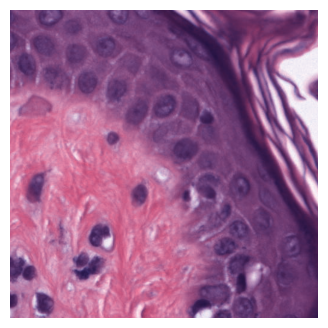

In [ ]:
#19.2. Run pretrained image encoder on 1 patch.

# Load 1 image
patch = Image.open("/content/drive/MyDrive/WSI_CMU-1/normedMacenko_patches512x512/CMU-1_patch_53_normed.png").convert("RGB")
plt.figure(figsize=(4, 4))
plt.imshow(patch)
plt.axis("off");

# Convert the image to a normalized tensor
image_tensor = preprocess(patch)

# Add a batch dimension: (3, 224, 224) -> (1, 3, 224, 224)
batch = image_tensor.unsqueeze(0).to(device)

with torch.inference_mode():
    embedding = model(batch)

embedding = embedding.cpu().numpy()

print("Embedding shape:", embedding.shape)
print("First 10 values:", embedding[0, :10])

In [ ]:
#19.3. Run pretrained image encoder on all patches.
patch_dir = Path("/content/drive/MyDrive/WSI_CMU-1/normedMacenko_patches512x512/")

image_paths = sorted([
  p for p in patch_dir.iterdir()
  if p.suffix.lower() in {".png", ".jpg", ".jpeg"}])

print("Number of patches:", len(image_paths))

if len(image_paths) == 0:
  raise ValueError("No images found. Check patch_dir.")

# Batch analysis
from torch.utils.data import Dataset, DataLoader

class PatchDataset(Dataset):
  def __init__(self, paths, transform):
    self.paths = paths
    self.transform = transform

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, index):
    path = self.paths[index]

    with Image.open(path) as image:
      image = image.convert("RGB")
      tensor = self.transform(image)
    return tensor, str(path)

dataset = PatchDataset(image_paths, preprocess)

loader = DataLoader(
      dataset,
      batch_size=32,
      shuffle=False,
      num_workers=0)

all_embeddings = []
all_paths = []

with torch.inference_mode():
  for images, paths in loader:
    images = images.to(device)
    features = model(images)
    all_embeddings.append(features.cpu().numpy())
    all_paths.extend(paths)

embeddings = np.concatenate(all_embeddings, axis=0)
print("Embedding matrix:", embeddings.shape)

Embedding matrix: (96, 512)


In [ ]:
#19.4. Save the results.
output_dir = Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/")
output_dir.mkdir(parents=True, exist_ok=True)

# Embeddings
np.save(output_dir / "embeddings.npy", embeddings)

# Metadata table
metadata = pd.DataFrame({
  "patch_path": all_paths,
  "embedding_row": np.arange(len(all_paths))})

metadata.to_csv(output_dir / "patch_metadata.csv", index=False)

print("Saved embeddings and metadata.")

Saved embeddings and metadata.


In [ ]:
#20. Understand embeddings before classification.


# --
#Q45. What does one row represent?
#A45. Each row represents one patch.

#Q46. What does one column represent?
#A46. Each column represents an embedding feature.

#Q47. Are the 512 features individually interpretable as "nucleus", "lymphocyte", "collagen", etc.? Be careful here.
#A47. No they do not directly mean "lymphocyte", "necrosis ", "nucleus". They are learned numerical features (features vectors).

In [14]:
#21. Visualize the embeddings with PCA.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load data
embeddings = np.load(Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "embeddings.npy")
metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "CMU-1_patches_metadata.csv")

# Reduce 512 features to 2 dimensions
pca = PCA(n_components=3)
embedding_2d = pca.fit_transform(embeddings)

print("PCA shape:", embedding_2d.shape)
print("Explained variance ratio", pca.explained_variance_ratio_)
print("Variance explained by three components:",
    round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(5, 5))
plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    s=20,
    alpha=0.75)

plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("ResNet-18 patch embeddings")
plt.show()

# Save PCA coordinates to the metadata
metadata["PC1"] = embedding_2d[:, 0]
metadata["PC2"] = embedding_2d[:, 1]

metadata.to_csv(
  Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "patch_metadata_with_pca.csv",
  index=False)


In [16]:
#22.1. Color by your own annotation.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Manual annotation of patches:
  # Uninformative (mostly keratin) = 0.
  # Stroma (>75% patch surface) = 1.
  # Epithelium (>25% patch surface) = 2.

# metadata loading with PCA coordinates
metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "CMU-1_patches_metadata.csv", sep=";")

plt.figure(figsize=(7, 7))
scatter = plt.scatter(
    metadata["PC1"],
    metadata["PC2"],
    c=metadata["patch_type"],
    s=25,
    alpha=0.75,
)

# Add patch_id
for idx, row in metadata.iterrows():
    plt.text(
        row["PC1"] + 0.15,  # Léger décalage en X pour la lisibilité
        row["PC2"] + 0.15,  # Léger décalage en Y
        str(idx + 1),
        fontsize=8,
        alpha=0.8
    )

labels = ["Uninformative", "Stroma", "Epithelium", "Epithelium and stroma"]

plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("ResNet-18 patch embeddings")

plt.legend(handles=scatter.legend_elements()[0], labels=labels, title="Manual Annotations", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

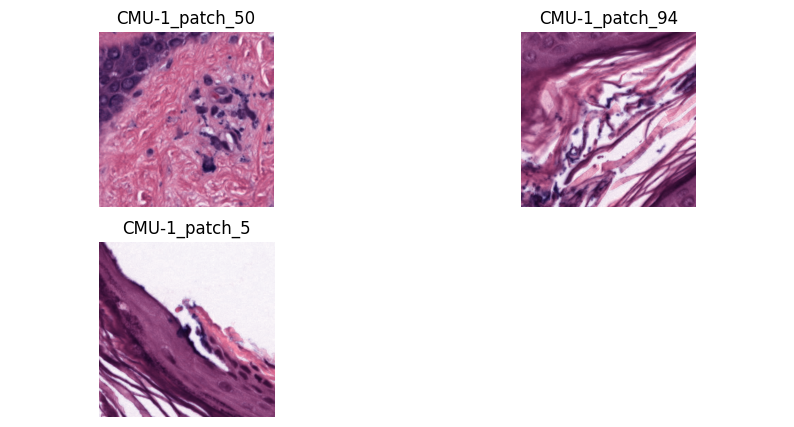

In [13]:
#22.2. Show corresponding patches.
patches = [50, 94, 5]

plt.figure(figsize=(10,5))
plt.axis("off")
for img in patches:
  plt.subplot(2, int(len(patches)/2+1), patches.index(img)+1)
  plt.imshow(plt.imread(f"/content/drive/MyDrive/WSI_CMU-1/normedMacenko_patches512x512/CMU-1_patch_{img}_normed.png"))
  plt.title(f"CMU-1_patch_{img}")
  plt.axis("off")

plt.show()

In [48]:
#23. Train a very simple classifier.
#24. Careful consideration about train/test leakage.

# Divide patches into train patches (80%) and test patches (20%)
from sklearn.model_selection import train_test_split

metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "CMU-1_patches_metadata.csv", sep=";")
embeddings = np.load(Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "embeddings.npy")

metadata_sorted = metadata.sort_values(by='embedding_row')

X_train, X_test, Y_train, Y_test = train_test_split(
    embeddings, # embeddings: array of shape (number_of_patches, 512)
    metadata_sorted["patch_type"], # labels: one label per patch, in the same order as embeddings
    test_size=0.2,
    random_state=42,
    stratify=metadata_sorted["patch_type"]
)

print("X_train = embeddings used to train the model:", X_train.shape)
print("Y_train = labels used to train the model:", Y_train.shape)
print("X_test = embeddings used to test the model:", X_test.shape)
print("Y_test = labels used as ground truth to evaluate perfomance:", Y_test.shape)

# Train the classifier and test it
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression(max_iter=1000) # Load the model
model.fit(X_train, Y_train) # Learn from the training data
Y_pred = model.predict(X_test) # Predict labels for held-out patches

print(classification_report(Y_test, Y_pred))


# --
#Q48. Why is random patch-level splitting potentially problematic?
#A48. A random train/test split can give misleadingly good results.
#Nearby patches often look similar, so the model may be tested on tissue very similar to what it saw during training.

#Q49. Why is patient/animal-level splitting preferable?
#A49. For a meaningful evaluation, it's generally better to train on slides from some animals and test on slides from different animals.

#Q50. If you have only one WSI, can you legitimately claim that your model generalizes to other animals?
#A50. No, overfitting may be significant and the model may not generalize well.

X_train = embeddings used to train the model: (76, 512)
Y_train = labels used to train the model: (76,)
X_test = embeddings used to test the model: (20, 512)
Y_test = labels used as ground truth to evaluate perfomance: (20,)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      0.80      0.89         5
           2       0.92      1.00      0.96        12

    accuracy                           0.95        20
   macro avg       0.97      0.93      0.95        20
weighted avg       0.95      0.95      0.95        20



```
#23. Train a very simple classifier.
#24. Careful consideration about train/test leakage.
```

1. Overview of the Metrics

* Precision: Out of all patches predicted to belong to a class, how many actually belonged to it. A high precision means few false positives.
* Recall: Out of all actual patches of a class, how many were correctly identified by the model. A high recall means few false negatives.
* F1-Score: The harmonic mean of precision and recall, representing a balanced overall measure of accuracy for that specific class.
* Support: The number of actual occurrences of each class in the test set (total of 20 patches in this split).

2. Class-by-Class Performance

* Class 0 (Uninformative / Keratin)

Precision: 1.00 | Recall: 1.00 | F1-Score: 1.00 | Support: 3

Explanation: The model achieved perfect performance on class 0. All 3 patches were correctly identified, and no other classes were misclassified as class 0.

* Class 1 (Stroma)

Precision: 1.00 | Recall: 0.80 | F1-Score: 0.89 | Support: 5

Explanation: The model has perfect precision (1.00), meaning every patch it predicted as Stroma was indeed Stroma. However, the recall is 0.80, which indicates that 1 out of the 5 actual Stroma patches (20%) was missed (misclassified as another class, likely Class 2).

* Class 2 (Epithelium)

Precision: 0.92 | Recall: 1.00 | F1-Score: 0.96 | Support: 12

Explanation: The model has perfect recall (1.00), meaning it successfully captured all 12 Epithelium patches. The slightly lower precision (0.92) confirms that it mistakenly classified one non-epithelium patch (the missed Stroma patch mentioned above) as Epithelium.

3. Summary Statistics

Accuracy (0.95): Overall, 19 out of 20 patches (95%) in the test set were classified correctly.

Macro Average (0.95 F1-score): Computes the metric independently for each class and then takes the average, treating all classes equally regardless of their support size.

Weighted Average (0.95 F1-score): Computes the average class metrics weighted by the support of each class, reflecting performance relative to the dataset's distribution.

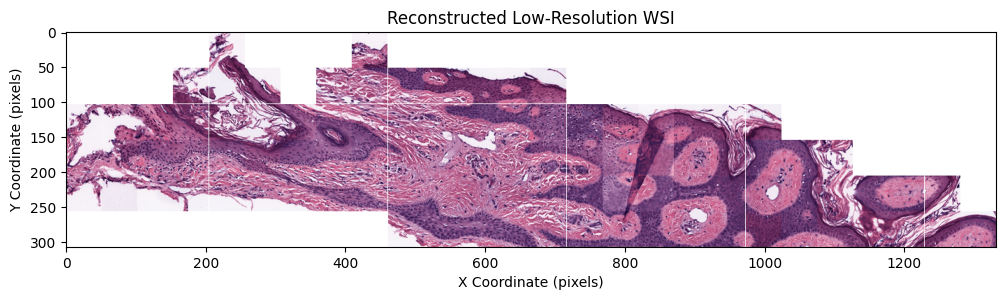

In [ ]:
#25. Create the AI map.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# 1. Retrieve the metadata with coordinates

# 2. Set scaling factor for low resolution (e.g., 0.1 to reduce resolution to 10%)

# Get coordinates and scale them

# Offset coordinates so that the minimum starts at 0

# 3. Calculate canvas size

# Create a blank white canvas

# 4. Paste each resized patch into the canvas

# 5. Display the low-resolution WSI canvas
